<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Face_verification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import os
import random
from pathlib import Path
from collections import defaultdict, Counter
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (2).json


{'kaggle (2).json': b'{"username":"nihat123","key":"2e3f5b2d33b88404948580c90d1b8ffd"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d stoicstatic/face-recognition-dataset
!unzip face-recognition-dataset.zip -d face_recognition_dataset

Dataset URL: https://www.kaggle.com/datasets/stoicstatic/face-recognition-dataset
License(s): CC0-1.0
face-recognition-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  face-recognition-dataset.zip
replace face_recognition_dataset/Extracted Faces/Extracted Faces/0/0.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
DATA_DIR = Path("/content/face_recognition_dataset")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
all_images = [
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in image_extensions
]


identity_to_images = defaultdict(list)

for img_path in all_images:
    identity = img_path.parent.name
    identity_to_images[identity].append(img_path)
identity_to_images = {
    identity: paths
    for identity, paths in identity_to_images.items()
    if len(paths) >= 2
}

In [ ]:
identity_to_images.keys()

dict_keys(['334', '892', '636', '947', '12', '549', '1272', '1413', '1123', '784', '515', '1452', '1271', '538', '247', '1000', '1004', '1182', '1577', '1013', '564', '1559', '463', '687', '490', '968', '517', '581', '1345', '262', '1280', '949', '1516', '78', '1211', '1677', '206', '1112', '1619', '207', '469', '114', '1114', '436', '617', '251', '1302', '1115', '455', '435', '1493', '641', '1432', '723', '692', '1561', '85', '91', '163', '539', '1200', '398', '211', '911', '1436', '1601', '133', '584', '155', '1015', '972', '523', '899', '252', '272', '72', '813', '214', '1061', '1226', '1178', '223', '1156', '202', '1396', '1470', '952', '475', '505', '752', '1518', '192', '175', '1511', '934', '1546', '1265', '1010', '1044', '46', '373', '1509', '781', '577', '240', '1152', '221', '1094', '637', '990', '236', '922', '237', '656', '909', '409', '615', '1367', '332', '1066', '255', '1159', '1587', '229', '477', '50', '627', '1255', '231', '1663', '0', '1207', '568', '1622', '1632', '

In [ ]:
def make_positive_pair(identity_to_images):
  identity=random.choice(list(identity_to_images.keys()))
  img1,img2=random.sample(identity_to_images[identity],2)
  return img1,img2,1

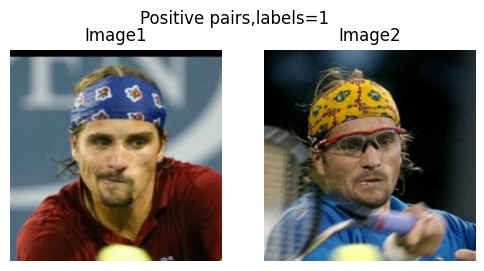

In [ ]:
img1,img2,label=make_positive_pair(identity_to_images)

plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plt.imshow(Image.open(img1).convert('RGB'))
plt.axis('off')
plt.title('Image1')

plt.subplot(1,2,2)
plt.imshow(Image.open(img2).convert("RGB"))
plt.axis('off')
plt.title('Image2')


plt.suptitle(f"Positive pairs,labels={label}")
plt.show()

In [ ]:
def make_negative_pair(identity_to_images):
  identity1,identity2=random.sample(list(identity_to_images.keys()),2)
  img1=random.choice(identity_to_images[identity1])
  img2=random.choice(identity_to_images[identity2])
  return img1,img2,0

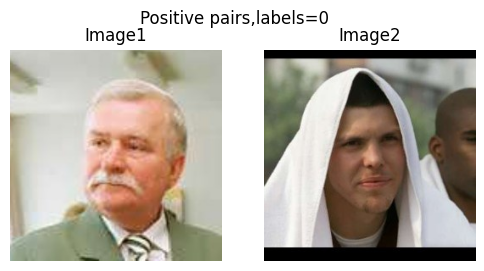

In [ ]:
img1,img2,label=make_negative_pair(identity_to_images)

plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plt.imshow(Image.open(img1).convert('RGB'))
plt.axis('off')
plt.title('Image1')

plt.subplot(1,2,2)
plt.imshow(Image.open(img2).convert("RGB"))
plt.axis('off')
plt.title('Image2')


plt.suptitle(f"Positive pairs,labels={label}")
plt.show()

In [ ]:
def create_pairs(identity_to_images,num_pairs=20000,positive_ratio=0.5,seed=42):
  random.seed(seed)
  pairs=[]
  labels=[]
  num_positive=int(num_pairs*positive_ratio)
  num_negative=num_pairs-num_positive
  for _ in range(num_positive):
    pairs.append(make_positive_pair(identity_to_images))
  for _ in range(num_negative):
    pairs.append(make_negative_pair(identity_to_images))
  random.shuffle(pairs)

  pairs_df=pd.DataFrame(pairs,columns=['img1','img2','label'])
  return pairs_df

pairs_df=create_pairs(identity_to_images,num_pairs=20000,positive_ratio=0.5)

pairs_df.head()

,img1,img2,label
0,/content/face_recognition_dataset/Face Data/Fa...,/content/face_recognition_dataset/Face Data/Fa...,1
1,/content/face_recognition_dataset/Extracted Fa...,/content/face_recognition_dataset/Extracted Fa...,0
2,/content/face_recognition_dataset/Extracted Fa...,/content/face_recognition_dataset/Extracted Fa...,0
3,/content/face_recognition_dataset/Face Data/Fa...,/content/face_recognition_dataset/Face Data/Fa...,1
4,/content/face_recognition_dataset/Extracted Fa...,/content/face_recognition_dataset/Extracted Fa...,1


In [ ]:
identities = list(identity_to_images.keys())
random.seed(42)
random.shuffle(identities)

n = len(identities)

train_ids = identities[:int(0.7 * n)]
val_ids = identities[int(0.7 * n):int(0.85 * n)]
test_ids = identities[int(0.85 * n):]

train_dict = {i: identity_to_images[i] for i in train_ids}
val_dict = {i: identity_to_images[i] for i in val_ids}
test_dict = {i: identity_to_images[i] for i in test_ids}

print("Train identities:", len(train_dict))
print("Val identities:", len(val_dict))
print("Test identities:", len(test_dict))

Train identities: 1176
Val identities: 252
Test identities: 252


In [ ]:
train_pairs = create_pairs(train_dict, num_pairs=30000, positive_ratio=0.5, seed=1)
val_pairs = create_pairs(val_dict, num_pairs=6000, positive_ratio=0.5, seed=2)
test_pairs = create_pairs(test_dict, num_pairs=6000, positive_ratio=0.5, seed=3)

print(train_pairs["label"].value_counts())
print(val_pairs["label"].value_counts())
print(test_pairs["label"].value_counts())

label
1    15000
0    15000
Name: count, dtype: int64
label
1    3000
0    3000
Name: count, dtype: int64
label
0    3000
1    3000
Name: count, dtype: int64


In [ ]:
IMG_SIZE = 128

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [ ]:
class FacePairDataset(Dataset):
  def __init__(self,pairs_df,transform=None):
    self.pairs_df=pairs_df.reset_index(drop=True)
    self.transform=transform
  def __len__(self):
    return len(self.pairs_df)
  def __getitem__(self, idx):
    row=self.pairs_df.iloc[idx]
    img1_path=row['img1']
    img2_path=row['img2']
    label=float(row['label'])

    img1=Image.open(img1_path).convert('RGB')
    img2=Image.open(img2_path).convert('RGB')

    if self.transform:
      img1=self.transform(img1)
      img2=self.transform(img2)

    label=torch.tensor(label,dtype=torch.float32)

    return img1,img2,label

In [ ]:
BATCH_SIZE = 64

train_dataset = FacePairDataset(train_pairs, transform=train_transform)
val_dataset = FacePairDataset(val_pairs, transform=eval_transform)
test_dataset = FacePairDataset(test_pairs, transform=eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [ ]:
img1,img2,labels=next(iter(train_loader))
print(img1.shape,img2.shape,labels.shape,labels[:10])

torch.Size([64, 3, 128, 128]) torch.Size([64, 3, 128, 128]) torch.Size([64]) tensor([1., 1., 1., 1., 0., 0., 0., 1., 0., 0.])


In [ ]:
class CNNEncoder(nn.Module):
    def __init__(self, embedding_dim=128):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 32 -> 16

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 16 -> 8
        )

        self.embedding = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 8 * 8, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, embedding_dim)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.embedding(x)
        x = F.normalize(x, p=2, dim=1)
        return x

In [ ]:
class SiameseNetwork(nn.Module):
    def __init__(self,embedding_dim=128):
        super().__init__()
        self.encoder =CNNEncoder(embedding_dim=embedding_dim)

    def forward(self, img1,img2):
        emb1 = self.encoder(img1)
        emb2 = self.encoder(img2)
        return emb1, emb2

In [ ]:
class ContrastiveLoss(nn.Module):
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin

    def forward(self, emb1, emb2, label):
      distance = F.pairwise_distance(emb1,emb2)

      positive_loss = label * torch.pow(distance, 2)
      negative_loss = (1-label) * torch.pow(torch.clamp(self.margin - distance, min=0.0),2)

      loss = torch.mean(positive_loss + negative_loss)
      return loss

In [ ]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=SiameseNetwork(embedding_dim=128).to(device)
criterion=ContrastiveLoss(margin=1.0)
optimizer=torch.optim.Adam(model.parameters(),lr=1e-4)

In [ ]:
img1,img2,labels=next(iter(train_loader))

img1=img1.to(device)
img2=img2.to(device)
labels=labels.to(device)

emb1,emb2=model(img1,img2)
loss=criterion(emb1,emb2,labels)
print(emb1.shape)
print(emb2.shape)
print(loss.item())

torch.Size([64, 128])
torch.Size([64, 128])
0.5928130149841309


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    all_distances = []
    all_labels = []

    for img1, img2, labels in tqdm(loader, desc="Training"):
        img1 = img1.to(device)
        img2 = img2.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        emb1, emb2 = model(img1, img2)
        loss = criterion(emb1, emb2, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * img1.size(0)

        distances = F.pairwise_distance(emb1, emb2)

        all_distances.extend(distances.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    all_distances = np.array(all_distances)
    all_labels = np.array(all_labels)

    pos_dist = all_distances[all_labels == 1].mean()
    neg_dist = all_distances[all_labels == 0].mean()

    return avg_loss, pos_dist, neg_dist

In [ ]:
@torch.no_grad()
def evaluate_distances(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_distances = []
    all_labels = []

    for img1, img2, labels in tqdm(loader, desc="Evaluating"):
        img1 = img1.to(device)
        img2 = img2.to(device)
        labels = labels.to(device)

        emb1, emb2 = model(img1, img2)
        loss = criterion(emb1, emb2, labels)

        total_loss += loss.item() * img1.size(0)

        distances = F.pairwise_distance(emb1, emb2)

        all_distances.extend(distances.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    all_distances = np.array(all_distances)
    all_labels = np.array(all_labels)

    pos_dist = all_distances[all_labels == 1].mean()
    neg_dist = all_distances[all_labels == 0].mean()

    return avg_loss, pos_dist, neg_dist, all_distances, all_labels

In [ ]:
def find_best_threshold(distances, labels):
    thresholds = np.linspace(distances.min(), distances.max(), 200)

    best_threshold = None
    best_f1 = -1
    best_metrics = None

    for threshold in thresholds:
        preds = (distances < threshold).astype(int)

        acc = accuracy_score(labels, preds)
        precision = precision_score(labels, preds, zero_division=0)
        recall = recall_score(labels, preds, zero_division=0)
        f1 = f1_score(labels, preds, zero_division=0)

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_metrics = {
                "accuracy": acc,
                "precision": precision,
                "recall": recall,
                "f1": f1
            }

    return best_threshold, best_metrics

In [ ]:
EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_pos_dist": [],
    "train_neg_dist": [],
    "val_pos_dist": [],
    "val_neg_dist": [],
    "val_f1": [],
    "val_acc": []
}

best_val_f1 = -1
best_threshold = None

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_pos_dist, train_neg_dist = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_pos_dist, val_neg_dist, val_distances, val_labels = evaluate_distances(
        model, val_loader, criterion, device
    )

    threshold, metrics = find_best_threshold(val_distances, val_labels)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_pos_dist"].append(train_pos_dist)
    history["train_neg_dist"].append(train_neg_dist)
    history["val_pos_dist"].append(val_pos_dist)
    history["val_neg_dist"].append(val_neg_dist)
    history["val_f1"].append(metrics["f1"])
    history["val_acc"].append(metrics["accuracy"])

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss:   {val_loss:.4f}")

    print(f"Train Positive Distance: {train_pos_dist:.4f}")
    print(f"Train Negative Distance: {train_neg_dist:.4f}")

    print(f"Val Positive Distance:   {val_pos_dist:.4f}")
    print(f"Val Negative Distance:   {val_neg_dist:.4f}")

    print(f"Best Threshold: {threshold:.4f}")
    print(
        f"Val Acc: {metrics['accuracy']:.4f} | "
        f"Precision: {metrics['precision']:.4f} | "
        f"Recall: {metrics['recall']:.4f} | "
        f"F1: {metrics['f1']:.4f}"
    )

    if metrics["f1"] > best_val_f1:
        best_val_f1 = metrics["f1"]
        best_threshold = threshold
        torch.save(model.state_dict(), "best_siamese_model.pth")
        print("Saved best model.")


Epoch 1/10


Evaluating: 100%|██████████| 94/94 [00:17<00:00,  5.45it/s]


Train Loss: 0.2365
Val Loss:   0.2157
Train Positive Distance: 0.4896
Train Negative Distance: 0.5391
Val Positive Distance:   0.3184
Val Negative Distance:   0.4823
Best Threshold: 0.4946
Val Acc: 0.6490 | Precision: 0.6045 | Recall: 0.8620 | F1: 0.7106
Saved best model.

Epoch 2/10


Evaluating: 100%|██████████| 94/94 [00:18<00:00,  5.08it/s]


Train Loss: 0.1901
Val Loss:   0.1858
Train Positive Distance: 0.4327
Train Negative Distance: 0.6375
Val Positive Distance:   0.3370
Val Negative Distance:   0.6007
Best Threshold: 0.5106
Val Acc: 0.7187 | Precision: 0.6767 | Recall: 0.8373 | F1: 0.7485
Saved best model.

Epoch 3/10


...

Train Loss: 0.1029
Val Loss:   0.1574
Train Positive Distance: 0.2889
Train Negative Distance: 0.8690
Val Positive Distance:   0.3770
Val Negative Distance:   0.8346
Best Threshold: 0.6640
Val Acc: 0.7797 | Precision: 0.7322 | Recall: 0.8820 | F1: 0.8001

Epoch 9/10


Evaluating: 100%|██████████| 94/94 [00:18<00:00,  5.10it/s]


Train Loss: 0.0961
Val Loss:   0.1528
Train Positive Distance: 0.2781
Train Negative Distance: 0.8964
Val Positive Distance:   0.3652
Val Negative Distance:   0.8617
Best Threshold: 0.7197
Val Acc: 0.7803 | Precision: 0.7213 | Recall: 0.9137 | F1: 0.8062
Saved best model.

Epoch 10/10


Evaluating: 100%|██████████| 94/94 [00:18<00:00,  5.13it/s]


Train Loss: 0.0909
Val Loss:   0.1589
Train Positive Distance: 0.2672
Train Negative Distance: 0.9149
Val Positive Distance:   0.3864
Val Negative Distance:   0.8842
Best Threshold: 0.7009
Val Acc: 0.7860 | Precision: 0.7370 | Recall: 0.8893 | F1: 0.8060
